In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Notebook có thể được chạy từ thư mục gốc project hoặc từ notebooks/
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw" / "Kvasir-SEG"
image_dir = data_dir / "images"
mask_dir = data_dir / "masks"

image_paths = sorted(image_dir.glob("*"))
print(f"Thư mục dữ liệu: {data_dir}")
print(f"Số ảnh: {len(image_paths)}")

Thư mục dữ liệu: c:\KI_1_NAM3_UET\hoc_sau\dl-project\Medical-Segmentation\data\raw\Kvasir-SEG
Số ảnh: 1000


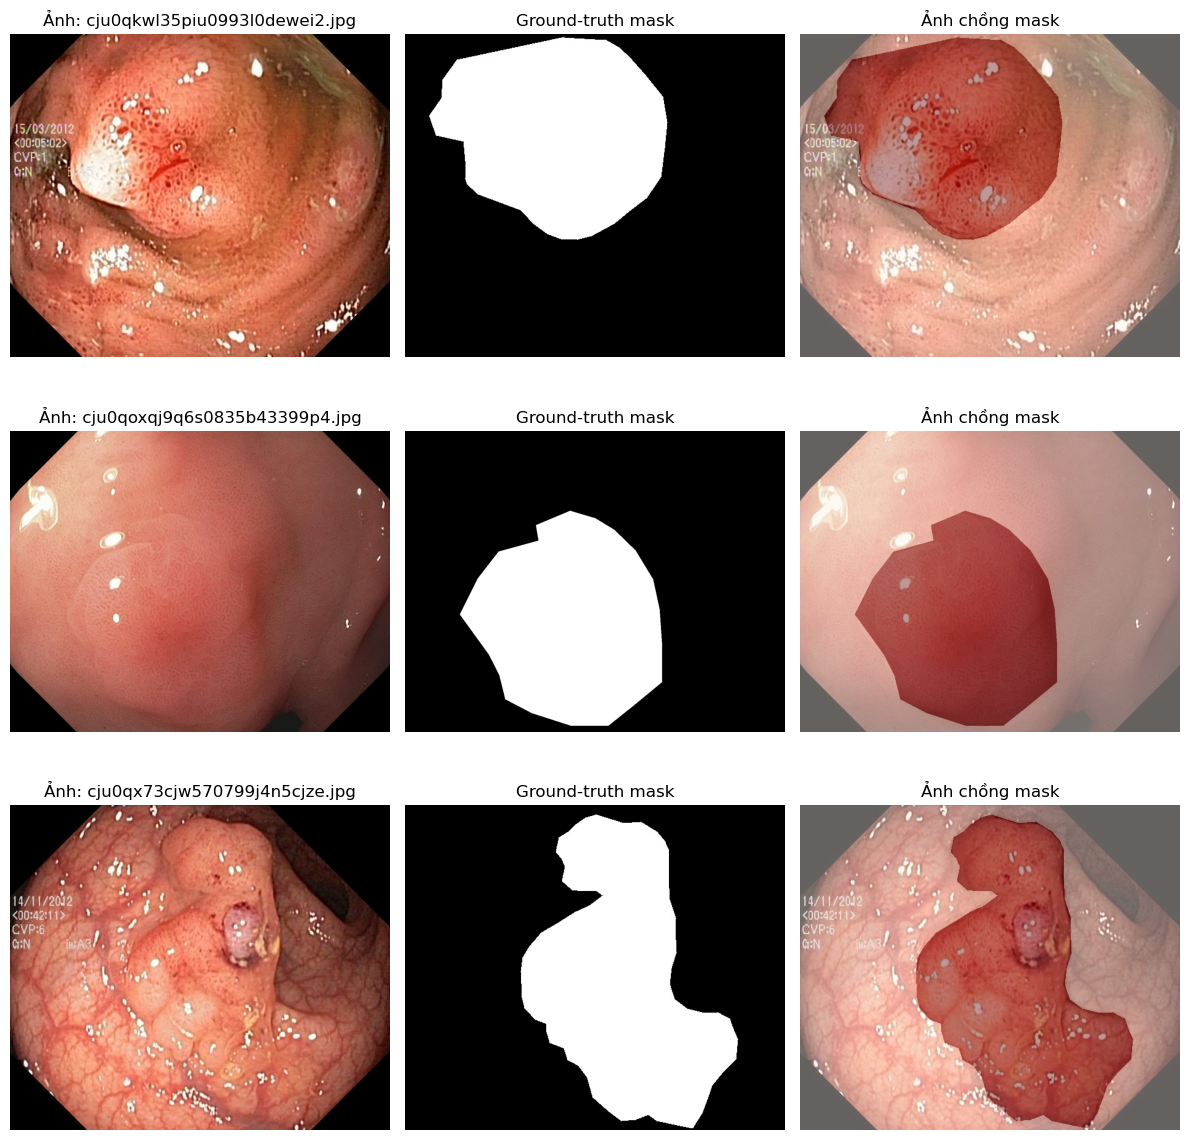

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, image_path in enumerate(image_paths[:3]):
    mask_path = mask_dir / image_path.name

    image = np.array(Image.open(image_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L"))

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Ảnh: {image_path.name}")

    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title("Ground-truth mask")

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(mask, cmap="Reds", alpha=0.4, vmin=0, vmax=255)
    axes[row, 2].set_title("Ảnh chồng mask")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
from collections import Counter

image_sizes = []
mask_sizes = []
mismatched_sizes = []
unreadable_files = []

for image_path in image_paths:
    mask_path = mask_dir / image_path.name

    try:
        with Image.open(image_path) as image:
            image_size = image.size  # (chiều rộng, chiều cao)

        with Image.open(mask_path) as mask:
            mask_size = mask.size

        image_sizes.append(image_size)
        mask_sizes.append(mask_size)

        if image_size != mask_size:
            mismatched_sizes.append(
                (image_path.name, image_size, mask_size)
            )

    except (OSError, ValueError) as error:
        unreadable_files.append((image_path.name, str(error)))

print(f"Số cặp đọc được: {len(image_sizes)}")
print(f"Số cặp lệch kích thước: {len(mismatched_sizes)}")
print(f"Số cặp gặp lỗi khi đọc: {len(unreadable_files)}")

print("\n5 kích thước ảnh phổ biến nhất (rộng, cao):")
for size, count in Counter(image_sizes).most_common(5):
    print(f"  {size}: {count} ảnh")

print("\nMột số cặp lệch kích thước:", mismatched_sizes[:5])
print("Một số cặp gặp lỗi:", unreadable_files[:5])

Số cặp đọc được: 1000
Số cặp lệch kích thước: 0
Số cặp gặp lỗi khi đọc: 0

5 kích thước ảnh phổ biến nhất (rộng, cao):
  (622, 530): 78 ảnh
  (626, 547): 66 ảnh
  (626, 546): 61 ảnh
  (622, 529): 56 ảnh
  (622, 528): 53 ảnh

Một số cặp lệch kích thước: []
Một số cặp gặp lỗi: []


In [5]:
# Đếm số pixel của từng mức xám từ 0 đến 255
pixel_counts = np.zeros(256, dtype=np.int64)
mask_value_examples = []

for image_path in image_paths:
    mask_path = mask_dir / image_path.name

    with Image.open(mask_path) as mask_file:
        mask = np.array(mask_file.convert("L"))

    pixel_counts += np.bincount(mask.ravel(), minlength=256)

    if len(mask_value_examples) < 3:
        mask_value_examples.append(
            (mask_path.name, np.unique(mask))
        )

print("Số mức xám xuất hiện:", np.count_nonzero(pixel_counts))
print("Tổng số pixel:", pixel_counts.sum())
print("Tỷ lệ pixel bằng 0:", pixel_counts[0] / pixel_counts.sum())
print("Tỷ lệ pixel bằng 255:", pixel_counts[255] / pixel_counts.sum())

print("\nGiá trị pixel trong 3 mask đầu:")
for name, values in mask_value_examples:
    print(f"{name}: {values}")

Số mức xám xuất hiện: 19
Tổng số pixel: 352050894
Tỷ lệ pixel bằng 0: 0.8398509932487205
Tỷ lệ pixel bằng 255: 0.15283189140261066

Giá trị pixel trong 3 mask đầu:
cju0qkwl35piu0993l0dewei2.jpg: [  0   1   2   3   4   5   6   7   8 247 248 249 250 251 252 253 254 255]
cju0qoxqj9q6s0835b43399p4.jpg: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
cju0qx73cjw570799j4n5cjze.jpg: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]


Tỷ lệ trung bình:  15.39%
Tỷ lệ trung vị:    11.40%
Nhỏ nhất:          0.47%
Lớn nhất:          81.18%
Số mask rỗng:      0
Số ảnh polyp < 1%: 6


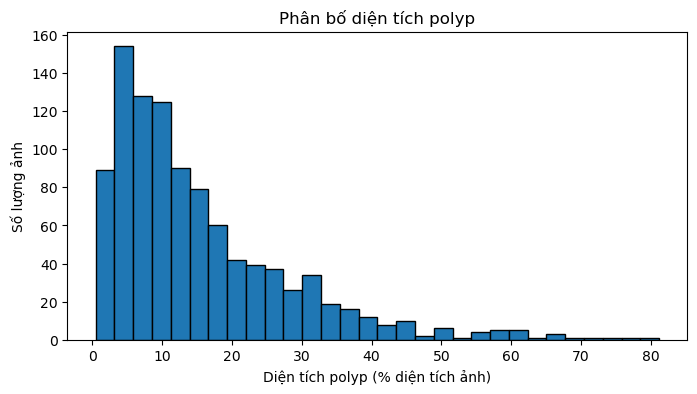

In [6]:
polyp_ratios = []

for image_path in image_paths:
    mask_path = mask_dir / image_path.name

    with Image.open(mask_path) as mask_file:
        mask = np.array(mask_file.convert("L"))

    # Giá trị >= 128 được xem là polyp
    binary_mask = mask >= 128
    polyp_ratios.append(binary_mask.mean())

polyp_ratios = np.array(polyp_ratios)

print(f"Tỷ lệ trung bình:  {polyp_ratios.mean():.2%}")
print(f"Tỷ lệ trung vị:    {np.median(polyp_ratios):.2%}")
print(f"Nhỏ nhất:          {polyp_ratios.min():.2%}")
print(f"Lớn nhất:          {polyp_ratios.max():.2%}")
print(f"Số mask rỗng:      {(polyp_ratios == 0).sum()}")
print(f"Số ảnh polyp < 1%: {(polyp_ratios < 0.01).sum()}")

plt.figure(figsize=(8, 4))
plt.hist(polyp_ratios * 100, bins=30, edgecolor="black")
plt.xlabel("Diện tích polyp (% diện tích ảnh)")
plt.ylabel("Số lượng ảnh")
plt.title("Phân bố diện tích polyp")
plt.show()

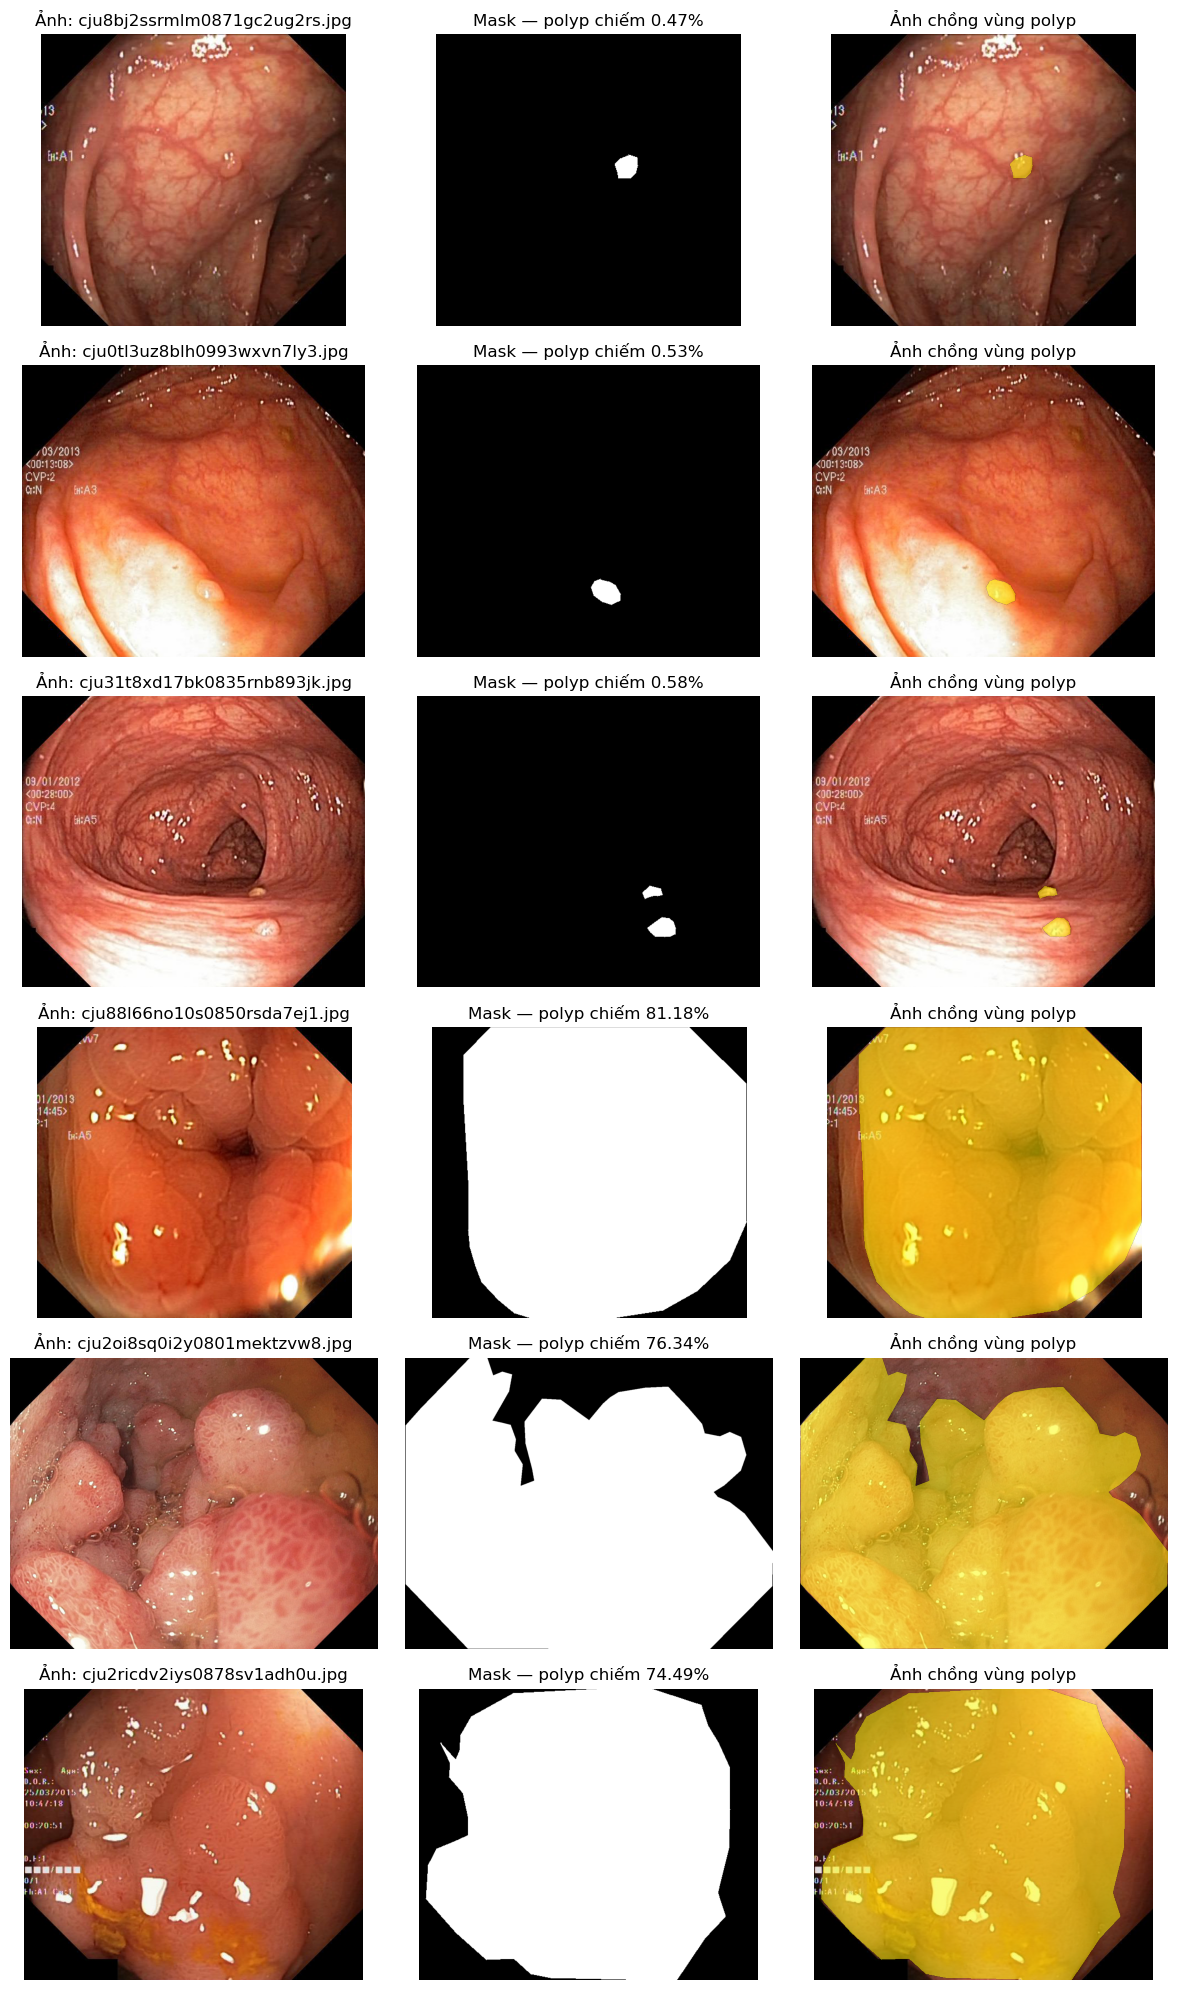

In [7]:
# Lấy vị trí của 3 mask có tỷ lệ polyp nhỏ nhất và lớn nhất
smallest_indices = np.argsort(polyp_ratios)[:3]
largest_indices = np.argsort(polyp_ratios)[-3:][::-1]
selected_indices = list(smallest_indices) + list(largest_indices)

fig, axes = plt.subplots(len(selected_indices), 3, figsize=(12, 20))

for row, idx in enumerate(selected_indices):
    image_path = image_paths[idx]
    mask_path = mask_dir / image_path.name

    with Image.open(image_path) as image_file:
        image = np.array(image_file.convert("RGB"))

    with Image.open(mask_path) as mask_file:
        mask = np.array(mask_file.convert("L"))

    binary_mask = mask >= 128

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Ảnh: {image_path.name}")

    axes[row, 1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"Mask — polyp chiếm {polyp_ratios[idx]:.2%}")

    axes[row, 2].imshow(image)
    # Chỉ tô màu tại vùng polyp
    overlay = np.ma.masked_where(~binary_mask, binary_mask)
    axes[row, 2].imshow(overlay, cmap="autumn", alpha=0.5, vmin=0, vmax=1)
    axes[row, 2].set_title("Ảnh chồng vùng polyp")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# Lấy tên file, đã sắp xếp từ bước EDA trước
filenames = [path.name for path in image_paths]

# Chia 80% train và 20% tạm thời
train_files, temp_files = train_test_split(
    filenames,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

# Chia 20% tạm thời thành 10% validation và 10% test
val_files, test_files = train_test_split(
    temp_files,
    test_size=0.5,
    random_state=42,
    shuffle=True,
)

print("Train:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))

Train: 800
Validation: 100
Test: 100


In [9]:
train_set = set(train_files)
val_set = set(val_files)
test_set = set(test_files)

print("Trùng giữa train và validation:", len(train_set & val_set))
print("Trùng giữa train và test:", len(train_set & test_set))
print("Trùng giữa validation và test:", len(val_set & test_set))
print("Tổng số ảnh duy nhất:", len(train_set | val_set | test_set))

# Chỉ lưu khi các tập không trùng và bao phủ toàn bộ ảnh
assert not (train_set & val_set), "Train và validation bị trùng!"
assert not (train_set & test_set), "Train và test bị trùng!"
assert not (val_set & test_set), "Validation và test bị trùng!"
assert train_set | val_set | test_set == set(filenames), "Thiếu hoặc thừa ảnh!"

split_dir = project_root / "data" / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

for split_name, files in [
    ("train", train_files),
    ("val", val_files),
    ("test", test_files),
]:
    split_path = split_dir / f"{split_name}.txt"
    split_path.write_text(
        "\n".join(sorted(files)) + "\n",
        encoding="utf-8",
    )
    print(f"Đã lưu: {split_path}")

Trùng giữa train và validation: 0
Trùng giữa train và test: 0
Trùng giữa validation và test: 0
Tổng số ảnh duy nhất: 1000
Đã lưu: c:\KI_1_NAM3_UET\hoc_sau\dl-project\Medical-Segmentation\data\splits\train.txt
Đã lưu: c:\KI_1_NAM3_UET\hoc_sau\dl-project\Medical-Segmentation\data\splits\val.txt
Đã lưu: c:\KI_1_NAM3_UET\hoc_sau\dl-project\Medical-Segmentation\data\splits\test.txt


In [10]:
import sys
import torch

# Cho phép notebook import code từ thư mục gốc project
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.datasets.polyp_dataset import PolypDataset

train_dataset = PolypDataset(
    data_dir=project_root / "data" / "raw" / "Kvasir-SEG",
    split_file=project_root / "data" / "splits" / "train.txt",
    image_size=(256, 256),
)

image, mask = train_dataset[0]

print("Số mẫu train:", len(train_dataset))
print("Kích thước ảnh:", image.shape)
print("Kích thước mask:", mask.shape)
print("Kiểu dữ liệu ảnh:", image.dtype)
print("Kiểu dữ liệu mask:", mask.dtype)
print("Khoảng giá trị ảnh:", image.min().item(), "đến", image.max().item())
print("Giá trị mask:", torch.unique(mask))

Số mẫu train: 800
Kích thước ảnh: torch.Size([3, 256, 256])
Kích thước mask: torch.Size([1, 256, 256])
Kiểu dữ liệu ảnh: torch.float32
Kiểu dữ liệu mask: torch.float32
Khoảng giá trị ảnh: 0.0 đến 1.0
Giá trị mask: tensor([0., 1.])


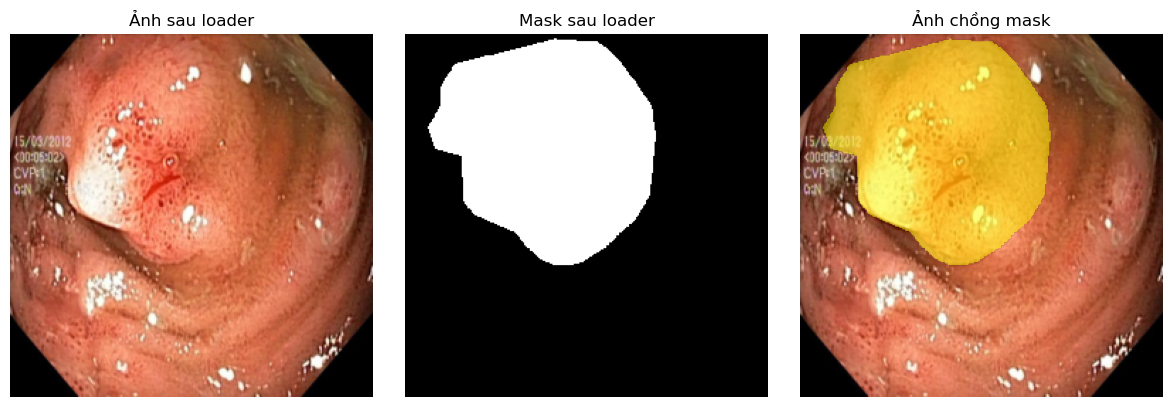

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Đổi ảnh từ (C, H, W) về (H, W, C) để hiển thị
image_display = image.permute(1, 2, 0).numpy()
mask_display = mask.squeeze(0).numpy()

axes[0].imshow(image_display)
axes[0].set_title("Ảnh sau loader")

axes[1].imshow(mask_display, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mask sau loader")

axes[2].imshow(image_display)
overlay = np.ma.masked_where(mask_display == 0, mask_display)
axes[2].imshow(overlay, cmap="autumn", alpha=0.5, vmin=0, vmax=1)
axes[2].set_title("Ảnh chồng mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
)

images, masks = next(iter(train_loader))

print("Kích thước batch ảnh:", images.shape)
print("Kích thước batch mask:", masks.shape)
print("Giá trị mask:", torch.unique(masks))

Kích thước batch ảnh: torch.Size([4, 3, 256, 256])
Kích thước batch mask: torch.Size([4, 1, 256, 256])
Giá trị mask: tensor([0., 1.])


In [13]:
data_dir = project_root / "data" / "raw" / "Kvasir-SEG"
split_dir = project_root / "data" / "splits"

val_dataset = PolypDataset(
    data_dir=data_dir,
    split_file=split_dir / "val.txt",
    image_size=(256, 256),
)

test_dataset = PolypDataset(
    data_dir=data_dir,
    split_file=split_dir / "test.txt",
    image_size=(256, 256),
)

val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0)

print("Số ảnh train:", len(train_dataset))
print("Số ảnh validation:", len(val_dataset))
print("Số ảnh test:", len(test_dataset))

Số ảnh train: 800
Số ảnh validation: 100
Số ảnh test: 100


In [14]:
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

# Xác định thư mục gốc project
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

archive_path = project_root / "polyp-training.zip"

# Các thư mục cần đưa vào ZIP
source_dirs = [
    project_root / "src",
    project_root / "data" / "raw" / "Kvasir-SEG" / "images",
    project_root / "data" / "raw" / "Kvasir-SEG" / "masks",
]

# Các file cần đưa vào ZIP
source_files = [
    project_root / "scripts" / "train.py",
    project_root / "data" / "splits" / "train.txt",
    project_root / "data" / "splits" / "val.txt",
    project_root / "data" / "splits" / "test.txt",
]

# Kiểm tra trước khi tạo ZIP
missing = [path for path in source_dirs + source_files if not path.exists()]

if missing:
    raise FileNotFoundError(
        "Không tìm thấy các đường dẫn sau:\n"
        + "\n".join(str(path) for path in missing)
    )

if archive_path.exists():
    raise FileExistsError(
        f"File ZIP đã tồn tại: {archive_path}\n"
        "Hãy đổi tên hoặc xóa file cũ trước khi chạy lại."
    )

file_count = 0

with ZipFile(archive_path, mode="x", compression=ZIP_DEFLATED) as archive:
    for source_dir in source_dirs:
        for path in sorted(source_dir.rglob("*")):
            if not path.is_file():
                continue

            # Bỏ qua file phát sinh của Python và file giữ thư mục rỗng
            if "__pycache__" in path.parts or path.suffix == ".pyc":
                continue
            if path.name == ".gitkeep":
                continue

            relative_path = path.relative_to(project_root)
            archive.write(path, arcname=Path("polyp-training") / relative_path)
            file_count += 1

    for path in source_files:
        relative_path = path.relative_to(project_root)
        archive.write(path, arcname=Path("polyp-training") / relative_path)
        file_count += 1

print(f"Đã tạo: {archive_path}")
print(f"Số file trong ZIP: {file_count}")
print(f"Kích thước ZIP: {archive_path.stat().st_size / 1024**2:.2f} MB")

Đã tạo: C:\KI_1_NAM3_UET\hoc_sau\dl-project\Medical-Segmentation\polyp-training.zip
Số file trong ZIP: 2021
Kích thước ZIP: 44.02 MB


In [15]:
with ZipFile(archive_path) as archive:
    names = archive.namelist()

    image_count = sum(
        name.startswith("polyp-training/data/raw/Kvasir-SEG/images/")
        for name in names
    )
    mask_count = sum(
        name.startswith("polyp-training/data/raw/Kvasir-SEG/masks/")
        for name in names
    )

    print("Số ảnh:", image_count)
    print("Số mask:", mask_count)

    for required in [
        "polyp-training/scripts/train.py",
        "polyp-training/src/models/unet.py",
        "polyp-training/data/splits/train.txt",
        "polyp-training/data/splits/val.txt",
        "polyp-training/data/splits/test.txt",
    ]:
        print(f"{'OK' if required in names else 'THIẾU'}: {required}")

Số ảnh: 1000
Số mask: 1000
OK: polyp-training/scripts/train.py
OK: polyp-training/src/models/unet.py
OK: polyp-training/data/splits/train.txt
OK: polyp-training/data/splits/val.txt
OK: polyp-training/data/splits/test.txt
